# PXR dose-response of 10 pure compounds: two replicate runs → 4PL fit with error bars

**Goal.** Take raw luciferase plate data for **pure** reference-hit compounds (batch AA-004) from the OpenADMET/Octant PXR HTChem blog-post repository, extract 10 compounds, fit a four-parameter logistic (4PL) curve to each, and plot every curve with error bars next to its 2D structure on identical axes.

**What is different from `dose_response_curve.ipynb`.**
- *Pure* compounds instead of crude library samples (the reference hits).
- Each compound was measured in **two independent runs** (OPA_PXR-032 and OPA_PXR-036), so every concentration has two wells (n = 2) and real error bars can be drawn.
- Pure hits are potent and often **roll over** (signal falls at high concentration), so the fit uses the rising limb only; excluded points stay visible as hollow markers.

**Assay and source.** PXR agonism in a GAL4-PXR reporter cell line (1536-well plates, 18–24 h compound incubation, Nano-Glo luciferase readout). The assay protocol, raw data and the authors' fits are in [OpenADMET/octant-pxr-htchem-blogpost](https://github.com/OpenADMET/octant-pxr-htchem-blogpost); the accompanying blog post, [Navigating PXR Chemical Space with High-Throughput Chemistry and Standard-Free Quantification](https://openadmet.github.io/octant-pxr-htchem-blogpost/), describes the experiments and the CAD yield correction of crude-sample potencies (the pure compounds here need no correction). The blog post does not describe the curve fitting; the fit below is independent of the authors'.

| Step | What happens | Output |
|---|---|---|
| 1–3 | Download both runs' raw wells, structures and the authors' pEC₅₀ | `data/source_*` |
| 4–6 | Select 10 compounds, save raw wells (both runs) as TSV, read back, pair replicates | `data/pxr_pure_raw_10cpds.tsv`, `data/pxr_pure_structures_10cpds.tsv` |
| 7–9 | Choose wells to fit, fit a 4PL per compound | `data/pxr_pure_fit_results_10cpds.tsv` |
| 10 | Plot curves + structures | `figures/pxr_pure_dose_response_10cpds.png` / `.pdf` |
| 11 | Cross-check against the authors' pEC₅₀ | inline figure |

**Units.**
- Concentration: µM (the raw file stores mol/L in `chem_m`).
- Response: luciferase signal normalised per plate, dimensionless: ≈ 0 at the negative-control (vehicle) level and 1 = the positive-control response (the dataset README states Emax is "normalized to the positive control").
- Potency: EC₅₀ in µM and pEC₅₀ = −log₁₀(EC₅₀ / M); higher pEC₅₀ = more potent.

## 1. Setup
Imports, source URLs, output paths and plotting style (dataviz reference palette: blue = data, orange = fit, neutral ink for all text).

In [1]:
import io
from pathlib import Path
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from PIL import Image
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from scipy import optimize, stats

# --- sources (OpenADMET/octant-pxr-htchem-blogpost, data/raw/)
BASE = "https://raw.githubusercontent.com/OpenADMET/octant-pxr-htchem-blogpost/main/data/raw/"
RAW_URLS = {   # raw per-well data of the two pure reference-hit runs
    "OPA_PXR-032": BASE + "drc/reference-hits/OPA_PXR-032_51622_reference_hits/stats.tsv",
    "OPA_PXR-036": BASE + "drc/reference-hits/OPA_PXR-036_53138_reference_hits/stats.tsv",
}
CORR_URL = BASE + "master/pxr-challenge_crude-sp-to-pure-correlation.csv"   # SMILES + authors' pEC50

# --- outputs
DATA, FIGS = Path("data"), Path("figures")
RAW_TSV = DATA / "pxr_pure_raw_10cpds.tsv"
STRUCT_TSV = DATA / "pxr_pure_structures_10cpds.tsv"
FIT_TSV = DATA / "pxr_pure_fit_results_10cpds.tsv"
N_COMPOUNDS = 10

# --- 4PL fit settings (step 8)
BOTTOM = None               # baseline fitted within ±0.2 (the 046 notebook fixes it at 0)
TOP_MAX = 3.0               # upper bound on the plateau (fraction of the positive control)
HILL_BOUNDS = (0.3, 5.0)

# --- style: dataviz reference palette (blue = measured data, orange = fit)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0dc"
plt.rcParams.update({
    "font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1.0, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 2. Load the raw plate data from both runs
Each `stats.tsv` has one row per well: plate position, compound, concentration (`chem_m`, mol/L), raw luminescence (`luci`, RLU) and `luci_norm` (the same signal rescaled per plate: (`luci` − plate negative-control mean) / (positive-control window), so the negative-control level is 0 and the positive-control level is 1; it is exactly linear in `luci` on every plate of both runs (verified). The positive-control wells themselves are not in the files). Rows with `compound_class == "Library"` are compound wells; the rest are negative-control wells. The two runs are stacked with a `run` column.

Each source file is downloaded once into its own folder under `data/`.

In [2]:
def download(url, folder, filename):
    # Fetch `url` once into data/<folder>/<filename>; later runs reuse the local copy.
    dest = DATA / folder / filename
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, dest)
    return dest


def load_run(run):
    # Compound wells of one run, with concentration converted to µM.
    df = pd.read_csv(download(RAW_URLS[run], f"source_{run}", "stats.tsv"), sep="\t",
                     na_values=["NA"], keep_default_na=False, dtype={"batch_name": str})
    df = df[df.compound_class == "Library"].copy()
    df["run"] = run
    df["conc_uM"] = df.chem_m * 1e6        # mol/L -> µM
    return df


raw = pd.concat([load_run(r) for r in RAW_URLS], ignore_index=True)
print(raw.groupby("run").agg(wells=("luci", "size"), compounds=("molecule_name", "nunique"),
                             batches=("batch_name", lambda s: ", ".join(sorted(s.unique())))).to_string())
raw.head(3)

             wells  compounds         batches
run                                          
OPA_PXR-032    169         19          AA-004
OPA_PXR-036    144         16  AA-001, AA-004


,plate,channel,row,col,molecule_name,batch_name,chem_id,chem_m,compound_class,luci,corrected,luci_norm,efdr,cell_line,run,conc_uM
0,Plate01,Luminescence,L,20,OCNT-2313323,AA-004,OCNT-2313323||NA|NA|AA-004,5.154000e-09,Library,118844,NaN,0.005141,NaN,c6385,OPA_PXR-032,0.005154
1,Plate01,Luminescence,M,20,OCNT-2313323,AA-004,OCNT-2313323||NA|NA|AA-004,1.544000e-08,Library,135169,NaN,0.026690,NaN,c6385,OPA_PXR-032,0.015440
2,Plate01,Luminescence,N,20,OCNT-2313323,AA-004,OCNT-2313323||NA|NA|AA-004,4.632000e-08,Library,193794,NaN,0.104072,NaN,c6385,OPA_PXR-032,0.046320


## 3. Load structures and the authors' reference pEC₅₀
The repository's crude-vs-pure correlation table gives the **SMILES** for the 2D drawings and the authors' pEC₅₀ for the pure compounds (`Pure pEC50s`, the mean of their runs). The pEC₅₀ is used only to choose compounds (step 4) and to cross-check the fits (step 11); it never enters the fitting.

In [3]:
corr = pd.read_csv(download(CORR_URL, "source_pure_correlation", "correlation.csv"))
ref = (pd.DataFrame({
           "molecule_name": corr["Compound ID"],
           "smiles": corr["SMILES"],
           "author_pEC50": pd.to_numeric(corr["Pure pEC50s (log)"], errors="coerce")})
       .drop_duplicates("molecule_name"))
ref.head(3)

,molecule_name,smiles,author_pEC50
0,OCNT-2395416,CCOC1=C(NC(=O)N2CCN(C3=NC(C(C)C)=CC=N3)CC2)C=C...,5.361917
1,OCNT-2314372,O=C(C1=CC=C(C2=C(C(F)(F)F)C=CC=C2)O1)N1C2CCCC1...,6.386158
2,OCNT-2316225,CC1=C(C(NC(=O)C2=CSC3=CN=CN23)C(C)(C)C)N=CC=C1,6.226945


## 4. Select 10 compounds
A fixed, reproducible rule, so the choice is not hand-picked:

1. **Eligible:** measured in **both** runs with a complete 9-point series in each, a maximum normalised response ≥ 0.5 in each run, and a SMILES and authors' pEC₅₀ available.
2. **Spread across potency:** sort eligible compounds by the authors' pEC₅₀ and take 10 evenly spaced ranks, from most to least potent.

In [4]:
per_run = raw.groupby(["molecule_name", "run"]).agg(
    n_points=("luci", "size"), max_response=("luci_norm", "max")).unstack("run")
both_runs_ok = ((per_run.n_points == 9) & (per_run.max_response >= 0.5)).all(axis=1)  # NaN (one run only) -> False

eligible = (ref[ref.molecule_name.isin(per_run.index[both_runs_ok]) & ref.author_pEC50.notna()]
            .sort_values("author_pEC50", ascending=False))
rank_idx = np.linspace(0, len(eligible) - 1, N_COMPOUNDS).round().astype(int)
assert len(set(rank_idx)) == N_COMPOUNDS, "not enough eligible compounds"
selected = eligible.iloc[rank_idx].reset_index(drop=True)

print(f"{raw.molecule_name.nunique()} compounds -> {len(eligible)} eligible -> {len(selected)} selected")
selected.round(2)

20 compounds -> 12 eligible -> 10 selected


,molecule_name,smiles,author_pEC50
0,OCNT-2309356,CC1CCN(C(=O)C2CC23CCC2=C3C=CC=C2)C2=C1C=CC=C2O,6.86
1,OCNT-2315472,CC1(NC(=O)C2=CC=C(S(=O)(=O)NC3CC3)C=C2)CC=CCC1,6.68
2,OCNT-2318616,CC1=C(N2C=CC(NC(=O)NCCS(=O)(=O)NC3=CC=CC=C3)=N...,6.63
3,OCNT-2317134,CCN1C=CN=C1C1CCCCN1C(=O)C1=CC2=C(C=C1)NC(C)=C2C,6.47
4,OCNT-2311117,C=CCC1(C(=O)NC2CCN(C(=O)OC(C)(C)C)CC2CO)CCCCC1,6.32
5,OCNT-2316441,CC1=C2C(=CC=C1)N(C(=O)C1=NNC(C3=CC=CO3)=C1)CCN...,6.26
6,OCNT-2318311,COC1=C(N2N=CC(C(=O)NCC3(CC4=CC=C(F)C=C4)CC3)=C...,6.22
7,OCNT-2308531,CCC(C)OC1=NC=CC(C(=O)N2CCC(C)C3=CC=CC(O)=C23)=C1,6.20
8,OCNT-2308748,COC(C)(C(=O)N1CCN(C2=NC(C(C)C)=CC=N2)CC1)C1=CC...,6.14
9,OCNT-2315950,CN1N=C2C=C(Br)C=CC2=C1C(=O)N1CCN(C)C2=C1C=CC(F...,5.87


## 5. Extract the raw wells and save as TSV
Keep both runs' wells for the 10 selected compounds and the columns needed for fitting. `luci` (raw RLU) is kept next to `luci_norm` so the raw values stay available. Structures go in a separate small TSV.

In [5]:
DATA.mkdir(exist_ok=True)
keep_cols = ["run", "plate", "row", "col", "molecule_name", "batch_name",
             "chem_m", "conc_uM", "luci", "luci_norm"]
extract = (raw[raw.molecule_name.isin(selected.molecule_name)][keep_cols]
           .sort_values(["molecule_name", "run", "conc_uM"]))

extract.to_csv(RAW_TSV, sep="\t", index=False)
selected[["molecule_name", "smiles"]].to_csv(STRUCT_TSV, sep="\t", index=False)
print(f"saved {len(extract)} wells for {extract.molecule_name.nunique()} compounds -> {RAW_TSV}")

saved 180 wells for 10 compounds -> data/pxr_pure_raw_10cpds.tsv


## 6. Read the TSV back and pair the replicates
From here on only the saved files are used. The two runs used the same 9-step dilution series with slightly different rounding (e.g. top concentration 49.5 vs 50 µM), so each well is assigned to its nearest **nominal dose level** (0–8, nominal values taken from run 036). Per compound and level, `levels` holds the mean, SD and n of the replicate wells; these give the error bars.

In [6]:
wells = pd.read_csv(RAW_TSV, sep="\t", keep_default_na=False, dtype={"batch_name": str})
structures = pd.read_csv(STRUCT_TSV, sep="\t")
assert len(wells) == len(extract) and wells.molecule_name.nunique() == N_COMPOUNDS

# nominal dilution series (µM) from run 036; assign each well to the nearest level on a log scale
first = wells[wells.run == "OPA_PXR-036"].molecule_name.iloc[0]
nominal = np.sort(wells[(wells.run == "OPA_PXR-036") & (wells.molecule_name == first)].conc_uM.values)
wells["level"] = np.abs(np.log10(wells.conc_uM.values)[:, None] - np.log10(nominal)[None, :]).argmin(axis=1)
assert np.allclose(wells.conc_uM, nominal[wells.level], rtol=0.05), "a well is far from its nominal level"

levels = (wells.groupby(["molecule_name", "level"]).luci_norm
          .agg(mean="mean", sd="std", n="size").reset_index())          # sd uses n-1; n = 2 here
levels["conc_uM"] = nominal[levels.level]
print("replicate wells per (compound, dose level):", sorted(levels.n.unique()))
levels.head(4)

replicate wells per (compound, dose level): [np.int64(2)]


,molecule_name,level,mean,sd,n,conc_uM
0,OCNT-2308531,0,-0.013241,0.003056,2,0.005154
1,OCNT-2308531,1,0.016492,0.020804,2,0.015441
2,OCNT-2308531,2,0.044267,0.005136,2,0.046324
3,OCNT-2308531,3,0.157569,0.039545,2,0.154413


## 7. Choose the wells to fit: rising limb only
A 4PL curve cannot describe a signal that rises and then falls (typically cell toxicity or reporter shut-off at high concentration). Rule per compound, on the replicate means:

- find the dose level of the **peak** mean response;
- find the first higher level whose mean response is **below 80 % of the peak**;
- exclude that level and all higher ones from the fit.

If no level falls below 80 % of the peak, all wells are fitted. Excluded wells are still plotted (hollow markers).

In [7]:
def rollover_cutoff(mean_by_level, frac=0.8):
    # First dose level above the peak whose mean falls below frac x peak; None if there is none.
    peak = int(np.argmax(mean_by_level))
    for j in range(peak + 1, len(mean_by_level)):
        if mean_by_level[j] < frac * mean_by_level[peak]:
            return j
    return None


cutoff = {name: rollover_cutoff(g.sort_values("level")["mean"].values)
          for name, g in levels.groupby("molecule_name")}
cut_level = wells.molecule_name.map({k: (99 if v is None else v) for k, v in cutoff.items()})
wells["in_fit"] = wells.level < cut_level
levels["in_fit"] = levels.level < levels.molecule_name.map({k: (99 if v is None else v) for k, v in cutoff.items()})

print(f"{(~wells.in_fit).sum()} of {len(wells)} wells excluded as rollover; "
      f"{sum(v is not None for v in cutoff.values())} of {N_COMPOUNDS} compounds affected")

16 of 180 wells excluded as rollover; 7 of 10 compounds affected


## 8. Four-parameter logistic (4PL) model
$$y = \text{bottom} + \frac{\text{top}-\text{bottom}}{1 + 10^{(\log_{10}\text{EC}_{50}-\log_{10}c)\cdot h}}$$

Fitted in log₁₀(µM) space to the individual wells of both runs that step 7 kept (rollover wells excluded), with bounded least squares (`scipy.optimize.curve_fit`, trust-region) and five different starting EC₅₀ guesses; the lowest-error fit is kept.
- **Bounds:** bottom −0.2…0.2, top 0…3, Hill slope 0.3…5, log₁₀ EC₅₀ within one decade of the fitted concentration range. The baseline is left free here, unlike in `dose_response_curve.ipynb` (where it is fixed at 0): with 14–18 pooled wells per curve the data determine it, and fixing it did not improve the agreement with the authors for these 10 compounds.
- **Uncertainty:** two intervals are stored.
  (i) `pEC50_se` / `pEC50_ci95`: standard error from the fit covariance, 95 % CI = SE × t(0.975, n_wells_fit − 4). The authors use the normal approximation (1.96 × SE), which is slightly narrower.
  (ii) `pEC50_lo` / `pEC50_hi`: 95 % **profile-likelihood** interval: EC₅₀ is fixed on a grid, the other parameters are refitted, and the interval is where the sum of squares stays within the F-test threshold. It is asymmetric and, unlike the covariance CI, stays meaningful when a parameter sits on a bound. This is the interval shown in the tables and plots.
- **Bound-only reporting:** an end of the profile interval is *not* reported when the data do not close it: the threshold is not crossed within the EC₅₀ search range, or the crossing is set by the top cap rather than by the data. If the weak-potency end is open, only an upper limit is reported (`pEC50 ≤ x`, i.e. EC₅₀ ≥ y µM). The fitted value is then plateau-dependent, and no EC₅₀ marker is drawn.
- **`top_at_bound`:** `True` when the fitted `top` sits on its bound (0 or 3), i.e. the data did not determine the plateau, so `top` and EC₅₀ depend on the bound chosen (a different bound gives a different EC₅₀). Treat the pEC₅₀ of a flagged fit as unreliable whatever its quality label says.
- **Quality label:** `EC50 poorly constrained` (95 % CI wider than one log unit, e.g. when the two runs disagree), `full curve` (plateau reached at the top fitted concentration), `partial curve` (top is extrapolated), `EC50 above top conc.` or `EC50 below lowest conc.`.


In [8]:
def four_pl(log_conc, bottom, top, log_ec50, hill):
    # 4PL response at log10(concentration in µM).
    return bottom + (top - bottom) / (1.0 + 10.0 ** ((log_ec50 - log_conc) * hill))


def model_setup(x):
    # Free-parameter model and bounds; the baseline is fitted within ±0.2 if BOTTOM is None, else fixed at BOTTOM.
    if BOTTOM is None:
        names = ["bottom", "top", "log_ec50", "hill"]
        model = four_pl
        lower = [-0.2, 0.0, x.min() - 1, HILL_BOUNDS[0]]
        upper = [0.2, TOP_MAX, x.max() + 1, HILL_BOUNDS[1]]
    else:
        names = ["top", "log_ec50", "hill"]
        model = lambda lc, top, log_ec50, hill: four_pl(lc, BOTTOM, top, log_ec50, hill)
        lower = [0.0, x.min() - 1, HILL_BOUNDS[0]]
        upper = [TOP_MAX, x.max() + 1, HILL_BOUNDS[1]]
    return names, model, np.array(lower), np.array(upper)


def profile_interval(x, y, names, model, lower, upper, popt, sse_min, step=0.02, level=0.95):
    # Profile-likelihood 95% interval for log10(EC50): fix EC50 on a grid, refit the other parameters, and find where
    # the sum of squares crosses the F-test threshold. Returns (weaker-potency end, stronger-potency end) in log10 EC50;
    # a side is None if the data do not close it: no crossing inside the EC50 search range, or the crossing is set by
    # the top cap rather than by the data.
    i, i_top = names.index("log_ec50"), names.index("top")
    keep = [j for j in range(len(names)) if j != i]
    dof = len(y) - len(names)
    crit = sse_min * (1.0 + stats.f.ppf(level, 1, dof) / dof)

    def refit(g, q0):
        lo, hi = lower[keep], upper[keep]
        res = optimize.least_squares(lambda q: y - model(x, *np.insert(q, i, g)),
                                     np.clip(q0, lo + 1e-9, hi - 1e-9), bounds=(lo, hi))
        return 2 * res.cost, res.x

    ends = {}
    for sign, edge in ((+1, upper[i]), (-1, lower[i])):
        q, g_prev, s_prev, end = popt[keep], popt[i], sse_min, None
        n_steps = int(abs(edge - popt[i]) / step)
        for g in np.append(popt[i] + sign * step * np.arange(1, n_steps + 1), edge):
            s, q = refit(g, q)
            if s > crit:
                crossing = g_prev + (crit - s_prev) / (s - s_prev) * (g - g_prev)     # linear interpolation
                at_cap = np.isclose(q[keep.index(i_top)], upper[i_top], rtol=0, atol=1e-3)
                end = None if at_cap else crossing
                break
            g_prev, s_prev = g, s
        ends[sign] = end
    return ends[+1], ends[-1]


def pec50_report(pec50, lo, hi):
    # Text for tables: a two-sided 95% range, or a one-sided bound when the weak-potency end is not closed.
    if np.isfinite(lo) and np.isfinite(hi):
        return f"{pec50:.2f} ({lo:.2f}–{hi:.2f})"
    if np.isfinite(hi):
        return f"≤ {hi:.2f}"
    return "not bounded"


def fit_4pl(conc_uM, response):
    # Fit one curve; returns parameters, pEC50, its covariance SE / 95% CI half-width and the profile-likelihood range.
    x, y = np.log10(conc_uM), np.asarray(response, float)
    names, model, lower, upper = model_setup(x)
    best = None
    for start in np.linspace(x.min(), x.max(), 5):          # guard against local minima
        p0 = {"bottom": np.clip(y.min(), -0.19, 0.19), "top": np.clip(y.max(), 0.05, TOP_MAX - 0.1),
              "log_ec50": start, "hill": 1.0}
        try:
            popt, pcov = optimize.curve_fit(model, x, y, p0=[p0[n] for n in names],
                                            bounds=(lower, upper), max_nfev=20000)
        except RuntimeError:
            continue
        sse = float(np.sum((y - model(x, *popt)) ** 2))
        if best is None or sse < best[0]:
            best = (sse, popt, pcov)
    sse, popt, pcov = best
    par = dict(zip(names, popt))
    bottom, top, log_ec50, hill = par.get("bottom", BOTTOM), par["top"], par["log_ec50"], par["hill"]

    with np.errstate(invalid="ignore"):
        se = np.sqrt(np.diag(pcov))[names.index("log_ec50")]  # SE of log10(EC50)
    se = se if np.isfinite(se) else np.nan
    ci95 = stats.t.ppf(0.975, len(y) - len(names)) * se
    # Flag a `top` pinned to its bound (0 or TOP_MAX): the data did not set it, so `top` and EC50 are bound-driven.
    top_at_bound = bool(np.any(np.isclose(top, [0.0, TOP_MAX], rtol=0, atol=1e-6)))

    weak, strong = profile_interval(x, y, names, model, lower, upper, popt, sse)
    pec50 = 6.0 - log_ec50                                   # log10(µM) -> -log10(M)
    lo = np.nan if weak is None else 6.0 - weak              # pEC50 lower limit (weak-potency end)
    hi = np.nan if strong is None else 6.0 - strong          # pEC50 upper limit
    return dict(bottom=bottom, top=top, hill=hill, log_ec50=log_ec50,
                ec50_uM=10 ** log_ec50, pEC50=pec50,
                pEC50_se=se, pEC50_ci95=ci95, rmse=np.sqrt(sse / len(y)), top_at_bound=top_at_bound,
                pEC50_lo=lo, pEC50_hi=hi, pEC50_report=pec50_report(pec50, lo, hi))


def fit_quality(fit, conc_uM):
    # Label how well the data constrain the curve.
    if fit["pEC50_ci95"] > 1.0:
        return "EC50 poorly constrained"          # 95% CI wider than one log unit (> 10-fold)
    if fit["ec50_uM"] > conc_uM.max():
        return "EC50 above top conc."
    if fit["ec50_uM"] < conc_uM.min():
        return "EC50 below lowest conc."
    y_top = four_pl(np.log10(conc_uM.max()), fit["bottom"], fit["top"], fit["log_ec50"], fit["hill"])
    return "full curve" if y_top >= fit["bottom"] + 0.9 * (fit["top"] - fit["bottom"]) else "partial curve"

## 9. Fit all 10 compounds
One fit per compound on the wells selected in step 7. The table is sorted from most to least potent and also shows the number of wells fitted and excluded, the lowest excluded concentration (`rollover_from_uM`), the authors' pEC₅₀ (`author_pEC50`) and the difference (`delta_pEC50`). Results are saved to TSV with full precision.

In [9]:
rows = []
for name, g in wells.groupby("molecule_name"):
    fitted = g[g.in_fit].sort_values("conc_uM")
    fit = fit_4pl(fitted.conc_uM.values, fitted.luci_norm.values)
    rows.append({"molecule_name": name, "n_wells_fit": len(fitted), "n_wells_excluded": int((~g.in_fit).sum()),
                 "rollover_from_uM": nominal[cutoff[name]] if cutoff[name] is not None else np.nan,
                 **fit, "fit_quality": fit_quality(fit, fitted.conc_uM.values)})

fits = (pd.DataFrame(rows)
        .merge(structures, on="molecule_name")
        .merge(ref[["molecule_name", "author_pEC50"]], on="molecule_name")
        .sort_values("pEC50", ascending=False).reset_index(drop=True))
fits["delta_pEC50"] = fits.pEC50 - fits.author_pEC50
fits.to_csv(FIT_TSV, sep="\t", index=False)

fits[["molecule_name", "n_wells_fit", "n_wells_excluded", "rollover_from_uM", "ec50_uM", "pEC50",
      "pEC50_report", "hill", "top", "top_at_bound", "fit_quality", "author_pEC50", "delta_pEC50"]].round(2)

,molecule_name,n_wells_fit,n_wells_excluded,rollover_from_uM,ec50_uM,pEC50,pEC50_report,hill,top,top_at_bound,fit_quality,author_pEC50,delta_pEC50
0,OCNT-2309356,16,2,49.5,0.13,6.88,6.88 (6.69–7.15),1.24,0.82,False,full curve,6.86,0.03
1,OCNT-2315472,16,2,49.5,0.23,6.63,6.63 (6.46–6.80),0.87,0.84,False,full curve,6.68,-0.05
2,OCNT-2318616,16,2,49.5,0.24,6.63,6.63 (6.48–6.78),1.64,0.65,False,full curve,6.63,-0.00
3,OCNT-2317134,18,0,NaN,0.36,6.45,≤ 7.50,0.44,1.11,False,EC50 poorly constrained,6.47,-0.02
4,OCNT-2316441,16,2,49.5,0.54,6.26,6.26 (6.18–6.35),1.39,0.92,False,full curve,6.26,0.00
5,OCNT-2318311,14,4,16.5,0.65,6.19,≤ 6.47,1.38,0.78,False,full curve,6.22,-0.03
6,OCNT-2308748,18,0,NaN,0.65,6.19,6.19 (5.78–6.52),1.02,1.14,False,full curve,6.14,0.04
7,OCNT-2308531,18,0,NaN,0.70,6.15,6.15 (5.95–6.34),1.03,1.22,False,full curve,6.20,-0.04
8,OCNT-2311117,16,2,49.5,0.78,6.11,6.11 (5.63–6.34),0.77,1.19,False,full curve,6.32,-0.21
9,OCNT-2315950,16,2,49.5,1.23,5.91,5.91 (5.57–6.14),1.15,0.57,False,full curve,5.87,0.04


## 10. Plot: curve + 2D structure for each compound
Each panel stacks the RDKit drawing above the dose-response plot. **All 10 plots share the same x-limits (log µM) and y-limits**, set once from the data of all 10 compounds.

- **Filled dot with error bar:** mean ± SD of the two runs (n = 2) at that concentration.
- **Hollow dot:** mean of a rolled-over concentration, *excluded* from the fit.
- **Orange line:** 4PL fit to the individual wells of both runs, excluding the rolled-over wells (hollow dots), drawn over the fitted range. **Dotted line:** fitted EC₅₀ (drawn only where the 95 % profile-likelihood range is closed; otherwise the potency box gives only a bound, EC₅₀ ≥ … / pEC₅₀ ≤ …).

Panels run from most to least potent, left to right and top to bottom.

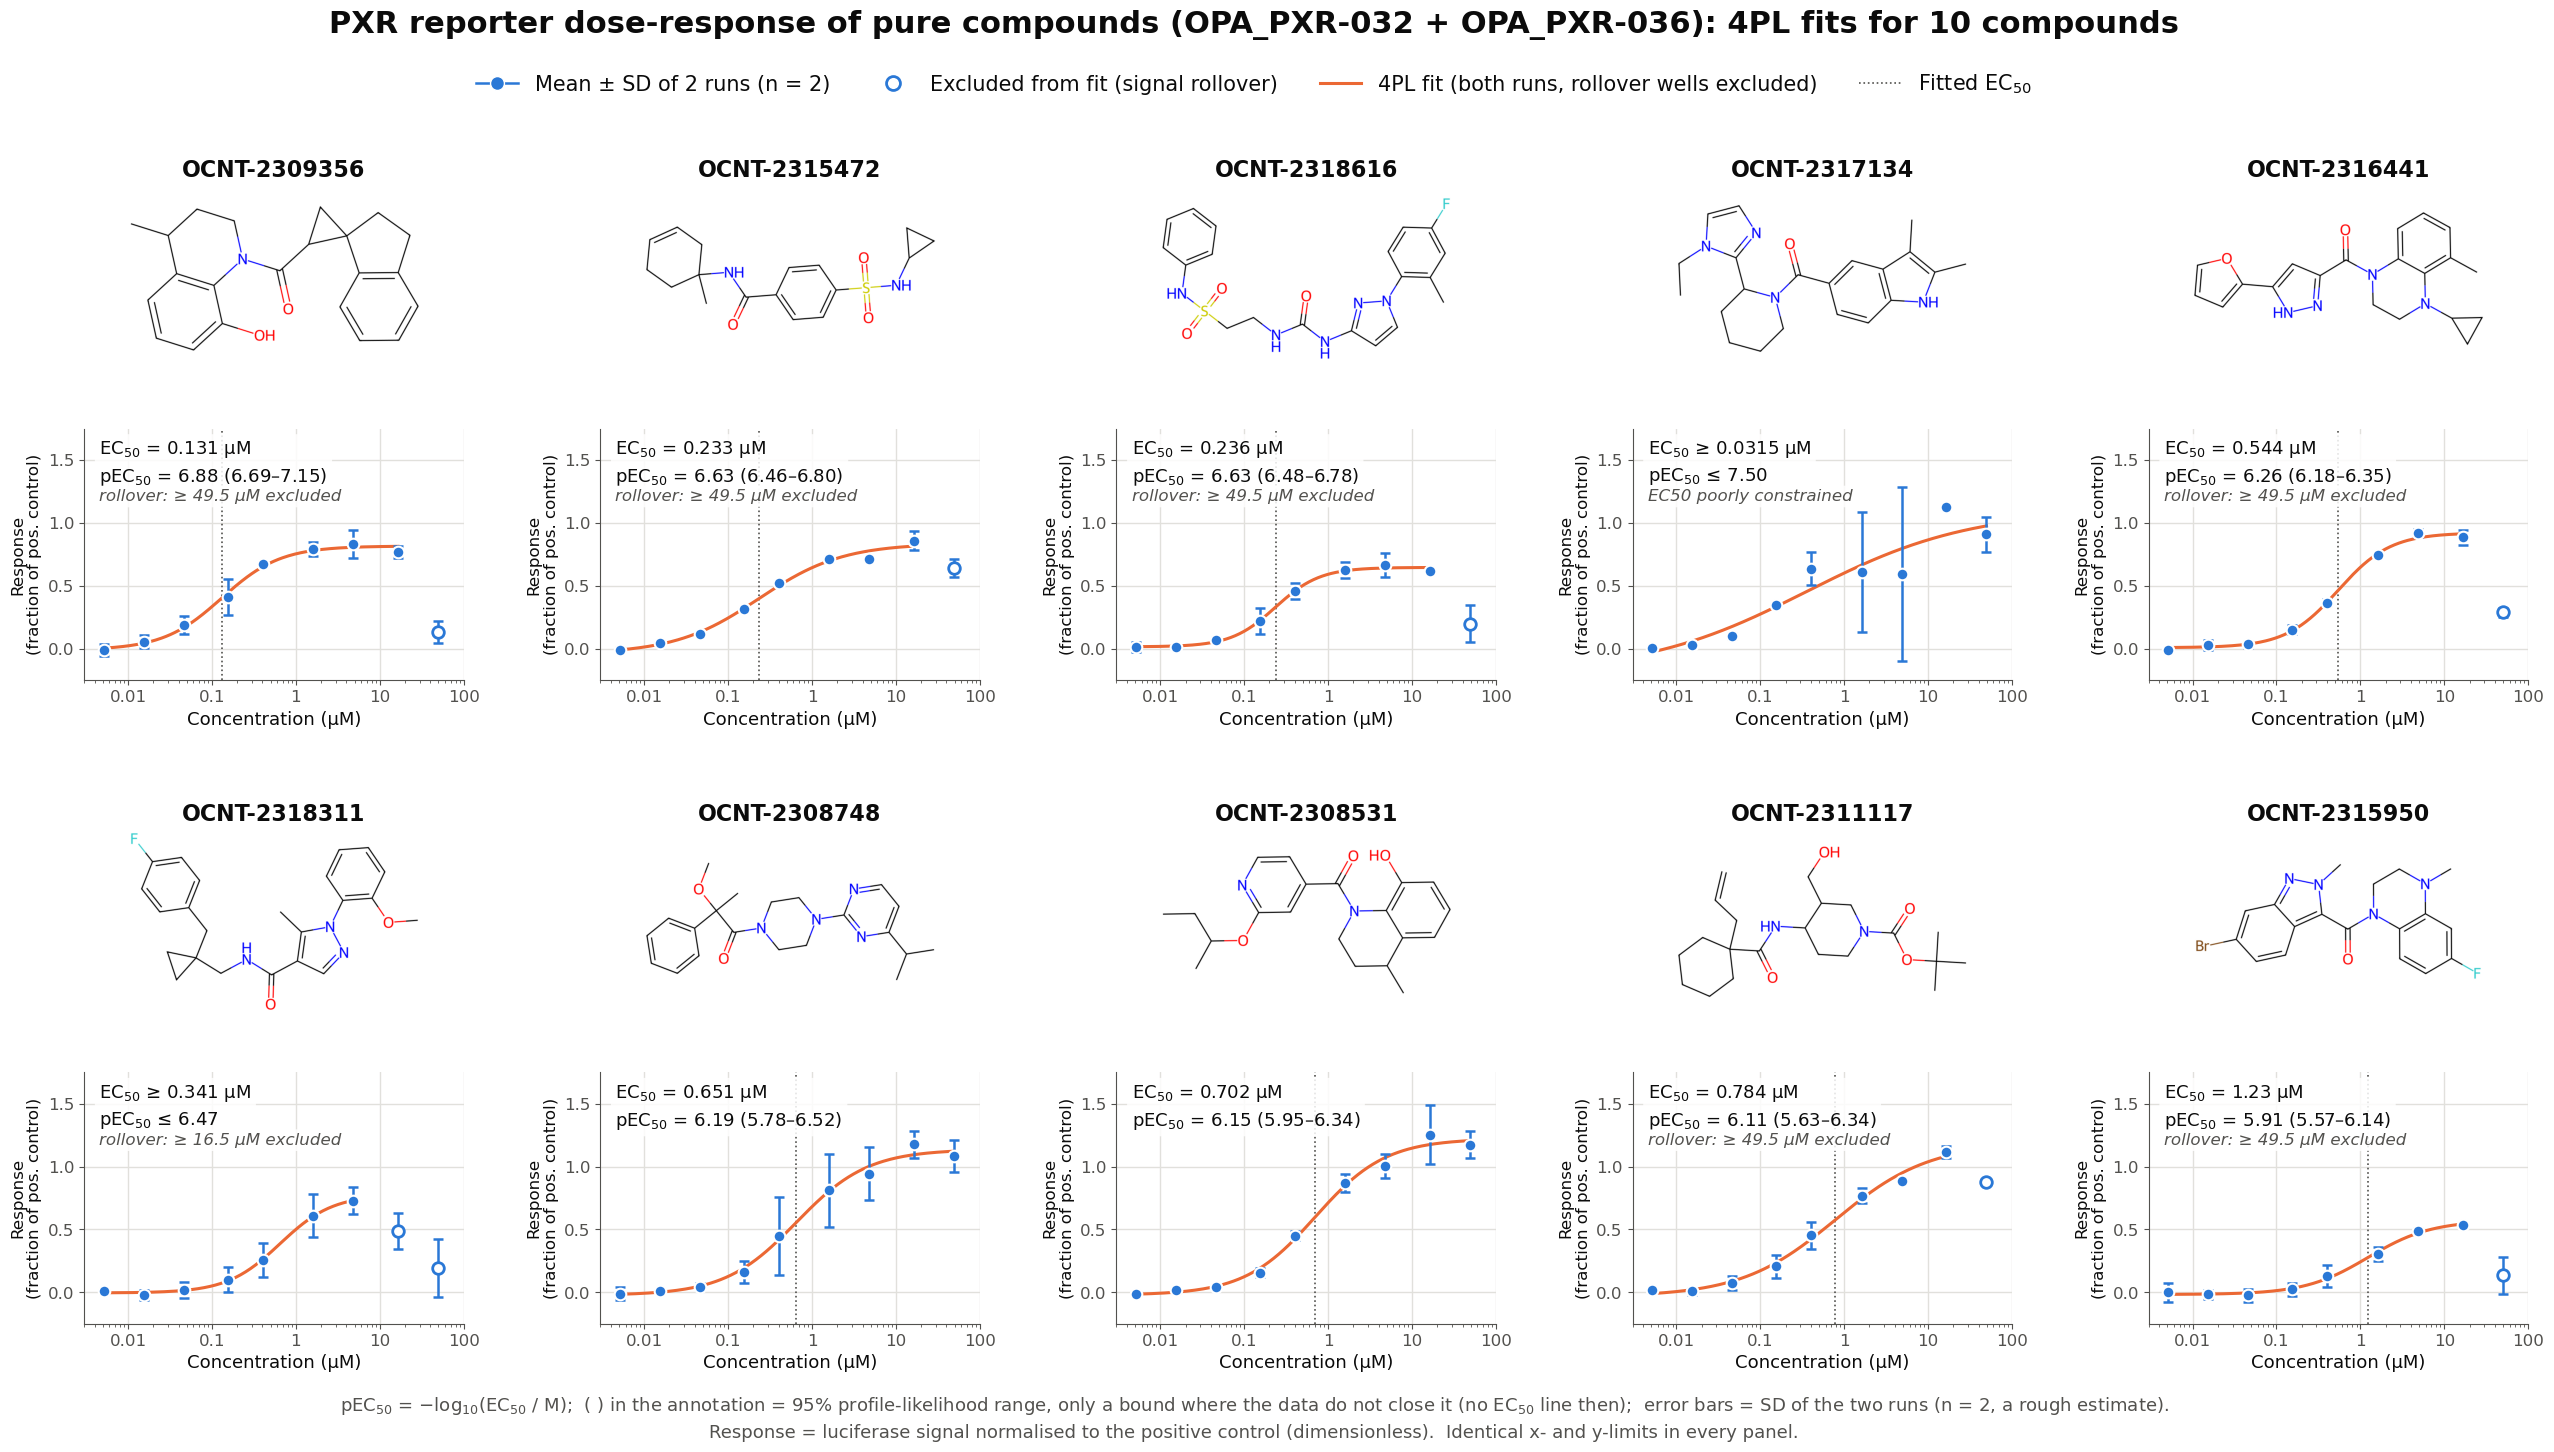

In [10]:
# --- shared axis limits for every panel (include the error-bar extents)
XLIM = (3e-3, 1e2)                                          # µM; the data span 0.005 – 50 µM
y_lo = min(wells.luci_norm.min(), (levels["mean"] - levels.sd.fillna(0)).min())
y_hi = max(wells.luci_norm.max(), (levels["mean"] + levels.sd.fillna(0)).max())
YLIM = (np.floor((y_lo - 0.03) / 0.25) * 0.25, np.ceil((y_hi + 0.10) / 0.25) * 0.25)   # 0.25 steps
YTICKS = np.arange(np.ceil(YLIM[0] / 0.5) * 0.5, YLIM[1] + 1e-9, 0.5)


def draw_structure(ax, smiles, title):
    # RDKit 2D depiction (large atom labels, thick bonds) with the compound ID as a bold heading.
    mol = Chem.MolFromSmiles(smiles)
    assert mol is not None, f"bad SMILES for {title}"
    drawer = rdMolDraw2D.MolDraw2DCairo(800, 500)
    opts = drawer.drawOptions()
    opts.baseFontSize, opts.bondLineWidth, opts.padding = 0.9, 3, 0.02
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    ax.imshow(Image.open(io.BytesIO(drawer.GetDrawingText())))
    ax.set_axis_off()
    ax.set_title(title, fontsize=16, fontweight="bold", color=INK, pad=6)


def potency_label(fit):
    # Potency text for a panel: EC50 and pEC50 with the 95% range, or only a bound when the range is not closed.
    if np.isfinite(fit.pEC50_lo) and np.isfinite(fit.pEC50_hi):
        return (f"EC$_{{50}}$ = {fit.ec50_uM:.3g} µM\n"
                f"pEC$_{{50}}$ = {fit.pEC50:.2f} ({fit.pEC50_lo:.2f}–{fit.pEC50_hi:.2f})")
    if np.isfinite(fit.pEC50_hi):
        return f"EC$_{{50}}$ ≥ {10 ** (6 - fit.pEC50_hi):.3g} µM\npEC$_{{50}}$ ≤ {fit.pEC50_hi:.2f}"
    return "EC$_{50}$ not bounded"


def draw_curve(ax, lv, fit, fit_conc):
    # Replicate means with SD error bars, 4PL fit, fitted-EC50 marker and potency annotation.
    xs = np.logspace(np.log10(fit_conc.min()), np.log10(fit_conc.max()), 200)
    ax.plot(xs, four_pl(np.log10(xs), fit.bottom, fit.top, fit.log_ec50, fit.hill),
            color=ORANGE, lw=2.2, zorder=2)
    closed = np.isfinite(fit.pEC50_lo) and np.isfinite(fit.pEC50_hi)       # 95% range closed on both sides
    if closed and XLIM[0] < fit.ec50_uM < XLIM[1]:
        ax.axvline(fit.ec50_uM, color=MUTED, lw=1.2, ls=":", zorder=1)
    ax.errorbar(lv.conc_uM, lv["mean"], yerr=lv.sd, fmt="none", ecolor=BLUE,
                elinewidth=1.8, capsize=3.5, capthick=1.8, zorder=3)
    used, dropped = lv[lv.in_fit], lv[~lv.in_fit]
    ax.scatter(used.conc_uM, used["mean"], s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=4)
    ax.scatter(dropped.conc_uM, dropped["mean"], s=70, facecolor="white", edgecolor=BLUE, linewidth=2, zorder=4)

    ax.text(0.04, 0.96, potency_label(fit),
            transform=ax.transAxes, va="top", ha="left", fontsize=13, linespacing=1.4,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    tags = ([f"rollover: ≥ {fit.rollover_from_uM:.3g} µM excluded"] if np.isfinite(fit.rollover_from_uM) else []) \
        + ([fit.fit_quality] if fit.fit_quality != "full curve" else [])
    if tags:                                   # notes sit under the potency box
        ax.text(0.04, 0.76, "\n".join(tags), transform=ax.transAxes, va="top", ha="left",
                fontsize=12, style="italic", color=MUTED, linespacing=1.4,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

    ax.set_xscale("log")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xticks([0.01, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(YTICKS)
    ax.set_xlabel("Concentration (µM)")
    ax.set_ylabel("Response\n(fraction of pos. control)", fontsize=12)


n_cols = 5
n_rows = int(np.ceil(len(fits) / n_cols))
fig = plt.figure(figsize=(26, 7.3 * n_rows), facecolor="white")
outer = fig.add_gridspec(n_rows, n_cols, hspace=0.30, wspace=0.36,
                         left=0.05, right=0.99, top=0.865, bottom=0.085)

for i, fit in fits.iterrows():
    inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // n_cols, i % n_cols],
                                    height_ratios=[1.3, 1.75], hspace=0.26)
    draw_structure(fig.add_subplot(inner[0]), fit.smiles, fit.molecule_name)
    name = fit.molecule_name
    draw_curve(fig.add_subplot(inner[1]), levels[levels.molecule_name == name].sort_values("level"), fit,
               wells[(wells.molecule_name == name) & wells.in_fit].conc_uM.values)

fig.suptitle("PXR reporter dose-response of pure compounds (OPA_PXR-032 + OPA_PXR-036): 4PL fits for 10 compounds",
             fontsize=22, fontweight="bold", y=0.985)
fig.legend(handles=[
    Line2D([], [], marker="o", ls="-", color=BLUE, markeredgecolor="white", markersize=10, lw=1.8, label="Mean ± SD of 2 runs (n = 2)"),
    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=BLUE, markeredgewidth=2, markersize=10, label="Excluded from fit (signal rollover)"),
    Line2D([], [], color=ORANGE, lw=2.2, label="4PL fit (both runs, rollover wells excluded)"),
    Line2D([], [], color=MUTED, lw=1.2, ls=":", label="Fitted EC$_{50}$"),
], loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=4, frameon=False, fontsize=15)
fig.text(0.5, 0.004, "pEC$_{50}$ = −log$_{10}$(EC$_{50}$ / M);  ( ) in the annotation = 95% profile-likelihood range, only a bound where the data do not close it "
         "(no EC$_{50}$ line then);  error bars = SD of the two runs (n = 2, a rough estimate).\n"
         "Response = luciferase signal normalised to the positive control (dimensionless).  Identical x- and y-limits in every panel.",
         ha="center", va="bottom", fontsize=13, color=MUTED, linespacing=1.5)

FIGS.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(FIGS / f"pxr_pure_dose_response_10cpds.{ext}", dpi=150, facecolor="white")
plt.show()

## 11. Cross-check against the authors' pEC₅₀
The authors' value is the mean of their own per-run fits. Points near the dashed identity line mean the joint fit here agrees with theirs; offsets can come from how rollover points are handled. Hollow points are fits for which only a bound on pEC₅₀ is reported; the plotted value is the fitted one.

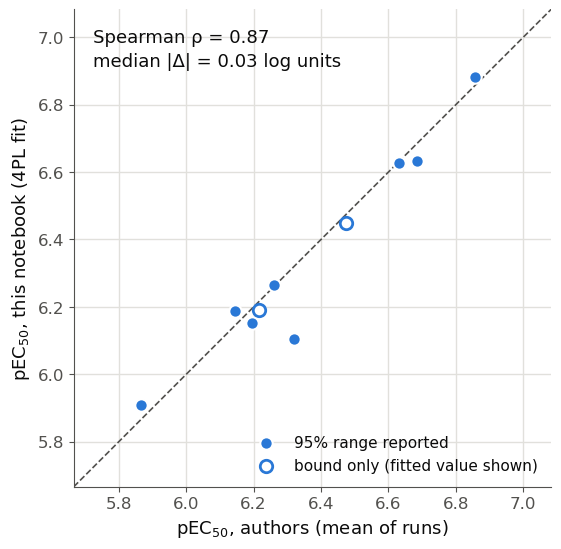

In [11]:
fig2, ax = plt.subplots(figsize=(6.5, 6.2), facecolor="white")
lim = (fits[["pEC50", "author_pEC50"]].min().min() - 0.2, fits[["pEC50", "author_pEC50"]].max().max() + 0.2)
ax.plot(lim, lim, color=MUTED, lw=1.2, ls="--", zorder=1)
closed = fits.pEC50_lo.notna() & fits.pEC50_hi.notna()      # 95% range closed on both sides
ax.scatter(fits.author_pEC50[closed], fits.pEC50[closed], s=80, color=BLUE, edgecolor="white", linewidth=1.5,
           zorder=3, label="95% range reported")
ax.scatter(fits.author_pEC50[~closed], fits.pEC50[~closed], s=80, facecolor="white", edgecolor=BLUE, linewidth=2,
           zorder=3, label="bound only (fitted value shown)")
if (~closed).any():
    ax.legend(loc="lower right", frameon=False, fontsize=11)
ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect("equal")
ax.set_xlabel("pEC$_{50}$, authors (mean of runs)")
ax.set_ylabel("pEC$_{50}$, this notebook (4PL fit)")

rho = stats.spearmanr(fits.pEC50, fits.author_pEC50).statistic
ax.text(0.04, 0.96, f"Spearman ρ = {rho:.2f}\nmedian |Δ| = {fits.delta_pEC50.abs().median():.2f} log units",
        transform=ax.transAxes, va="top", fontsize=13, linespacing=1.4)
plt.show()

## Notes and limitations
- **n = 2:** an SD from two values is a rough estimate of spread; the error bars show run-to-run agreement, not a precise confidence interval. The fit intervals use the wells kept for fitting (`n_wells_fit` − 4 degrees of freedom), i.e. without the rolled-over wells; the covariance CI uses t(0.975, `n_wells_fit` − 4) where the authors use 1.96 × SE.
- **Runs are pooled:** both runs are normalised per plate to the positive control and used the same pure batch (AA-004), so wells are fitted together; systematic run-to-run offsets would widen the residuals. Where the runs disagree strongly the fit is flagged `EC50 poorly constrained` and its pEC₅₀ should not be over-interpreted.
- **Rollover rule** (step 7) is a pragmatic choice: it fits the rising limb, so EC₅₀ describes activation before signal loss and says nothing about the descending phase.
- **Bound-only fits:** where the data do not close the weak-potency end of the profile interval (plateau not determined), only an upper limit on pEC₅₀ is reported; see step 8.
- **Selection** is by rule (step 4), not a random or exhaustive sample of the reference hits.